In [1]:
%pip install pandas numpy scikit-learn matplotlib
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Задача: Классификация задержек авиарейсов

**Датасет:** 2015 Flight Delays and Cancellations (Kaggle, US DOT) — исторические данные о рейсах за 2015 год.

**Тип задачи:** Бинарная классификация

**Размер данных:** подвыборка 500 000 рейсов, 31 исходный признак

**Признаки:** месяц, день, день недели, авиакомпания, аэропорт вылета, аэропорт прилёта, запланированное время вылета, расстояние.

**Цель:** по информации о рейсе, известной до вылета, определить, будет ли рейс задержан (прилёт с опозданием > 15 минут).

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, ConfusionMatrixDisplay)

RANDOM_STATE = 42
path = 'flights.csv'

print("Размер файла на диске, МБ:", round(os.path.getsize(path) / 1024**2, 2))
df_full = pd.read_csv(path, low_memory=False)
df = df_full.sample(n=500_000, random_state=RANDOM_STATE).reset_index(drop=True)

print("Полный файл:", df_full.shape)
print("Подвыборка:", df.shape)
print("Первые 5 строк")
display(df.head())

print("\nРаспределение по месяцам в подвыборке:")
print(df['MONTH'].value_counts().sort_index())

Размер файла на диске, МБ: 564.96
Полный файл: (5819079, 31)
Подвыборка: (500000, 31)
Первые 5 строк


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,4,7,2,EV,4900,N759EV,FWA,DTW,1340,...,1423.0,-13.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,24,6,AS,611,N413AS,LAS,SEA,1910,...,2133.0,-12.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,7,8,3,WN,1483,N463WN,OAK,SEA,630,...,812.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,5,26,2,WN,193,N7745A,STL,DAL,810,...,1222.0,152.0,0,0,NaN,0.0,0.0,0.0,152.0,0.0
4,2015,7,6,1,UA,253,N213UA,IAH,HNL,1000,...,1316.0,-2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN



Распределение по месяцам в подвыборке:
MONTH
1     40480
2     36963
3     43292
4     41685
5     42679
6     43330
7     44603
8     43507
9     40119
10    41880
11    40462
12    41000
Name: count, dtype: int64


### 1. Чтение данных

Размер файла на диске — 564.96 МБ. Загружена подвыборка: 500 000 строк, 31 столбец.

В таблице есть четыре группы столбцов:

1. **Сведения о рейсе:** год, месяц, день, день недели, номер рейса,
   бортовой номер самолёта, авиакомпания (двухбуквенный код перевозчика),
   аэропорт вылета и аэропорт прилёта (трёхбуквенные коды городов).
2. **Расписание и время:** запланированное время вылета, фактическое время
   вылета, задержка вылета, время в воздухе, расстояние, запланированное
   и фактическое время прилёта, задержка прилёта.
3. **Статус рейса:** признак отмены, признак перенаправления, причина отмены.
4. **Причины задержки:** задержка по вине авиасистемы, по безопасности,
   по вине авиакомпании, из-за позднего прибытия борта, по погоде.

В первых 5 строках задержка прилёта — от −22 до +5 минут, отменённых
и перенаправленных рейсов нет. Столбцы с причинами задержки и причиной
отмены в этих строках пустые — они заполняются только когда рейс задержан
сильно или отменён.

**Какие столбцы идут в модель.** Только те, что известны до вылета:
месяц, день, день недели, авиакомпания, аэропорт вылета, аэропорт прилёта,
запланированное время вылета, расстояние. Задержка прилёта и задержка
вылета в признаки не берутся — они известны только после рейса, это была
бы утечка ответа в модель. Признаки отмены и перенаправления используются
только чтобы выбросить такие рейсы из выборки.

### 2. Разбиение на обучающую и тестовую выборки

Перед разбиением убираем отменённые и перенаправленные рейсы: у них не бывает
задержки прилёта, то есть нет целевой переменной. Такие строки нельзя
оставлять — модель не сможет по ним учиться.

Строим целевую переменную: `IS_DELAYED = 1`, если рейс прилетел с опозданием
больше 15 минут, иначе `0`. Порог 15 минут — стандартное определение
задержки у авиационных служб.

Признаки — только то, что известно до вылета. Делим данные на обучающую
(70%) и тестовую (30%) выборки. Стратифицированное разбиение сохраняет
доли классов в обеих частях.

In [3]:
df = df[(df['CANCELLED'] == 0) & (df['DIVERTED'] == 0)].copy()
df['IS_DELAYED'] = (df['ARRIVAL_DELAY'] > 15).astype(int)

print("=== Проверка дисбаланса ===")
print("Полный датасет, доля задержанных (ARRIVAL_DELAY > 15):",
      (df_full['ARRIVAL_DELAY'] > 15).mean().round(4))
print("Полный датасет, пропуски в ARRIVAL_DELAY:",
      df_full['ARRIVAL_DELAY'].isna().mean().round(4))
print("После фильтрации CANCELLED==0 & DIVERTED==0, доля IS_DELAYED==1:",
      df['IS_DELAYED'].mean().round(4))
print("После фильтрации, пропуски в ARRIVAL_DELAY:",
      df['ARRIVAL_DELAY'].isna().mean().round(4))

# сначала приводим аэропорты к строке
df['ORIGIN_AIRPORT'] = df['ORIGIN_AIRPORT'].astype(str)
df['DESTINATION_AIRPORT'] = df['DESTINATION_AIRPORT'].astype(str)

# только теперь берём признаки — они уже строковые
feature_cols = ['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE',
                'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
                'SCHEDULED_DEPARTURE', 'DISTANCE']
X = df[feature_cols]
y = df['IS_DELAYED']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

num_cols = ['MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DISTANCE']
cat_cols = ['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']

print("После фильтрации:", df.shape)
print("Обучающая выборка:", X_train.shape[0])
print("Тестовая выборка:", X_test.shape[0])
print("Числовые признаки:", num_cols)
print("Категориальные признаки:", cat_cols)
print("\nБаланс классов (train):")
print(y_train.value_counts(normalize=True).round(3))
print("\nБаланс классов (test):")
print(y_test.value_counts(normalize=True).round(3))

=== Проверка дисбаланса ===
Полный датасет, доля задержанных (ARRIVAL_DELAY > 15): 0.1759
Полный датасет, пропуски в ARRIVAL_DELAY: 0.0181
После фильтрации CANCELLED==0 & DIVERTED==0, доля IS_DELAYED==1: 0.1798
После фильтрации, пропуски в ARRIVAL_DELAY: 0.0
После фильтрации: (490984, 32)
Обучающая выборка: 343688
Тестовая выборка: 147296
Числовые признаки: ['MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DISTANCE']
Категориальные признаки: ['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']

Баланс классов (train):
IS_DELAYED
0    0.82
1    0.18
Name: proportion, dtype: float64

Баланс классов (test):
IS_DELAYED
0    0.82
1    0.18
Name: proportion, dtype: float64


### Анализ пункта 2

**Сколько строк осталось.** После удаления отменённых и перенаправленных
рейсов осталось 490 984 строки из 500 000 — потеряно около 1,8% данных.
Это ожидаемо: у отменённых и перенаправленных рейсов не бывает задержки
прилёта, поэтому их нельзя использовать для обучения.

**Размер выборок.** Обучающая — 343 688 рейсов, тестовая — 147 296.
Соотношение 70/30.

**Баланс классов.** Задержанных рейсов (опоздание больше 15 минут) —
18,0%, вовремя — 82,0%. Доли в обучающей и тестовой выборках совпадают
до третьего знака — стратификация сработала.

**Что это значит.** Классы несбалансированы: на одного задержанного
приходится примерно 4,5 рейса вовремя. Поэтому Accuracy сама по себе
будет завышена за счёт частого класса «вовремя» — модель, которая всегда
отвечает «вовремя», получит Accuracy около 0,82, но ни одной задержки
не поймает. Поэтому по ходу работы смотрим на матрицу рассогласования:
по ней видно, сколько настоящих задержек модель нашла, а сколько
пропустила.

**Признаки.** В модели 5 числовых признаков (месяц, день, день недели,
запланированное время вылета, расстояние) и 3 категориальных
(авиакомпания, аэропорт вылета, аэропорт прилёта). Категориальные дальше
закодируем one-hot, числовые — нормализуем.

### 3. Визуализация данных и основные характеристики

Смотрим на числовые признаки и на то, как задержки распределены
по авиакомпаниям и по месяцам. Строим описательные статистики,
гистограммы числовых признаков и долю задержек по категориям.

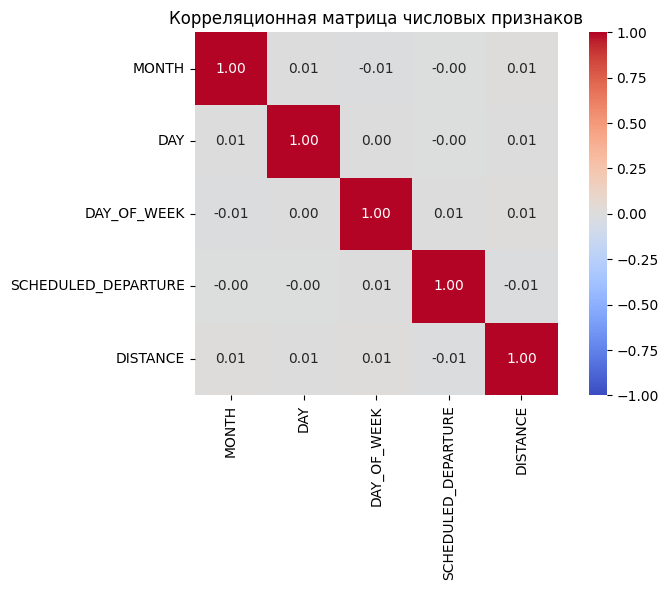

Взаимная корреляция числовых признаков:
                     MONTH    DAY  DAY_OF_WEEK  SCHEDULED_DEPARTURE  DISTANCE
MONTH                1.000  0.007       -0.008               -0.000     0.010
DAY                  0.007  1.000        0.005               -0.002     0.006
DAY_OF_WEEK         -0.008  0.005        1.000                0.005     0.015
SCHEDULED_DEPARTURE -0.000 -0.002        0.005                1.000    -0.009
DISTANCE             0.010  0.006        0.015               -0.009     1.000
Описательные статистики числовых признаков:
                        count     mean     std   min    25%     50%     75%  \
MONTH                343688.0     6.55    3.40   1.0    4.0     7.0     9.0   
DAY                  343688.0    15.71    8.78   1.0    8.0    16.0    23.0   
DAY_OF_WEEK          343688.0     3.93    1.98   1.0    2.0     4.0     6.0   
SCHEDULED_DEPARTURE  343688.0  1328.54  483.09   1.0  917.0  1325.0  1730.0   
DISTANCE             343688.0   823.77  607.41  31.0 

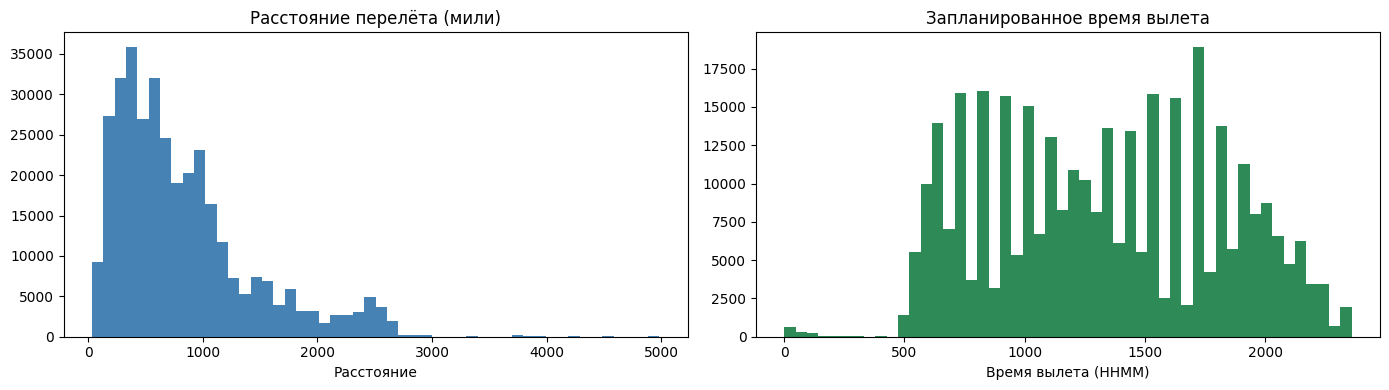

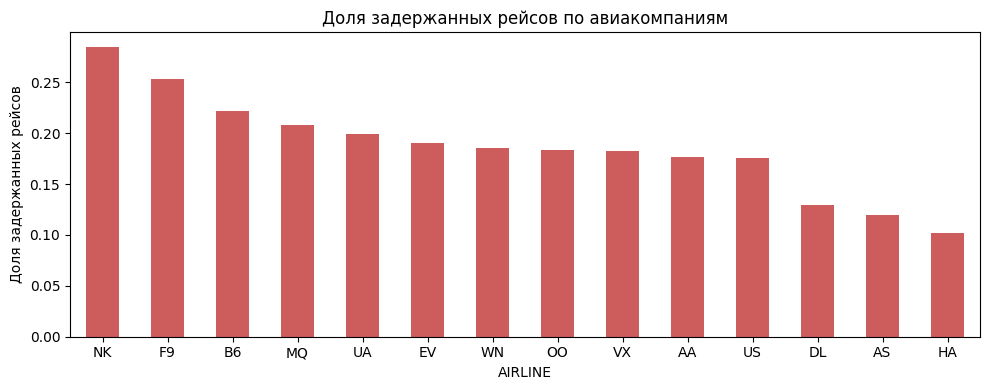

Доля задержек по авиакомпаниям:
AIRLINE
NK    0.285
F9    0.253
B6    0.222
MQ    0.208
UA    0.199
EV    0.191
WN    0.186
OO    0.184
VX    0.183
AA    0.177
US    0.176
DL    0.129
AS    0.119
HA    0.102
Name: IS_DELAYED, dtype: float64


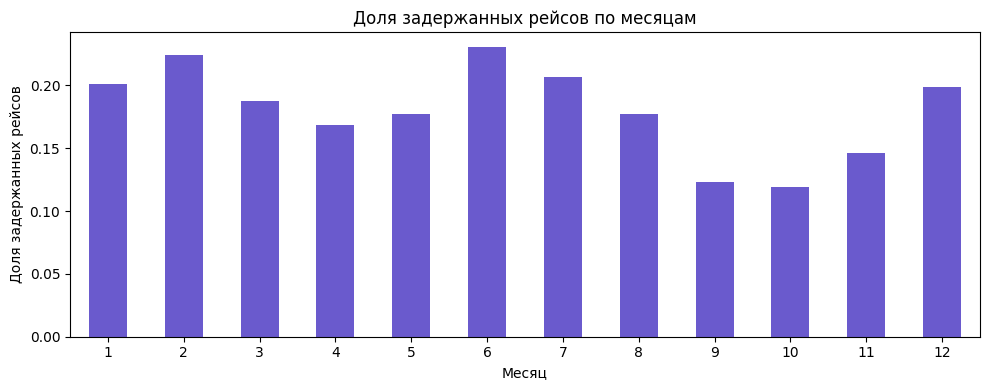

Доля задержек по месяцам:
MONTH
1     0.201
2     0.224
3     0.187
4     0.168
5     0.177
6     0.231
7     0.206
8     0.177
9     0.123
10    0.119
11    0.147
12    0.199
Name: IS_DELAYED, dtype: float64


In [4]:
import seaborn as sns

plt.figure(figsize=(8, 6))
# Вычисляем корреляцию Пирсона для числовых признаков
corr_matrix = X_train[num_cols].corr()

# Строим тепловую карту
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

print("Взаимная корреляция числовых признаков:")
print(corr_matrix.round(3))

print("Описательные статистики числовых признаков:")
print(X_train[num_cols].describe().T.round(2))

# Гистограммы числовых признаков
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(X_train['DISTANCE'], bins=50, color='steelblue')
axes[0].set_title('Расстояние перелёта (мили)')
axes[0].set_xlabel('Расстояние')
axes[1].hist(X_train['SCHEDULED_DEPARTURE'], bins=50, color='seagreen')
axes[1].set_title('Запланированное время вылета')
axes[1].set_xlabel('Время вылета (HHMM)')
plt.tight_layout()
plt.show()

# Доля задержек по авиакомпаниям
delay_by_airline = df.groupby('AIRLINE')['IS_DELAYED'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 4))
delay_by_airline.plot(kind='bar', color='indianred')
plt.title('Доля задержанных рейсов по авиакомпаниям')
plt.ylabel('Доля задержанных рейсов')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Доля задержек по авиакомпаниям:")
print(delay_by_airline.round(3))

# Доля задержек по месяцам
delay_by_month = df.groupby('MONTH')['IS_DELAYED'].mean()
plt.figure(figsize=(10, 4))
delay_by_month.plot(kind='bar', color='slateblue')
plt.title('Доля задержанных рейсов по месяцам')
plt.ylabel('Доля задержанных рейсов')
plt.xlabel('Месяц')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Доля задержек по месяцам:")
print(delay_by_month.round(3))

### Анализ пункта 3

**Описательные статистики.**

- **Месяц.** От 1 до 12, медиана 7 — все 12 месяцев представлены, выборка
  покрывает весь год. Это значит, что модель видит зимние, весенние,
  летние и осенние рейсы.
- **День месяца.** От 1 до 31, медиана 16 — дни распределены равномерно.
- **День недели.** От 1 до 7, медиана 4 — все дни недели представлены.
- **Запланированное время вылета.** От 1 до 2359 (формат HHMM), медиана
  1325 (13:25). Рейсы есть в любое время суток.
- **Расстояние.** От 31 до 4983 миль, медиана 649. Распределение с длинным
  правым хвостом: большинство перелётов средней длины, но есть редкие
  трансконтинентальные рейсы на 3000–5000 миль.

**Доля задержек по авиакомпаниям.** Разброс большой: от 0.285 (самая
проблемная авиакомпания) до 0.102 (самая пунктуальная). Это подтверждает,
что авиакомпания — информативный признак.

**Доля задержек по месяцам.** Видна сезонность: минимум в сентябре–октябре
(0.123 и 0.119), максимум в феврале (0.224) и июне (0.231). Разница между
самым спокойным и самым проблемным месяцем — почти в два раза. Значит,
месяц как признак несёт полезную информацию и его стоит оставить в модели.

**Анализ корреляционной матрицы:**
* На построенной тепловой карте видно, что между всеми числовыми признаками (`MONTH`, `DAY`, `DAY_OF_WEEK`, `SCHEDULED_DEPARTURE`, `DISTANCE`) линейная взаимосвязь полностью отсутствует. 
* Все коэффициенты корреляции Пирсона находятся в диапазоне от -0.02 до 0.02, то есть практически равны нулю. Это говорит о том, что признаки независимы друг от друга.


### 4-7. Предобработка данных

1. **Выбросы.** Проверяем числовые признаки по правилу IQR. Удалять
   не будем: выбросы в расстоянии и времени вылета — это реальные рейсы,
   а не ошибки ввода. Вместо удаления применяем нормализацию, чтобы
   выбросы не доминировали в расстоянии для KNN.
2. **Пропуски.** Проверяем, есть ли они в признаках. Если есть — заполняем
   медианой (числовые) или строкой `'Unknown'` (категориальные).
3. **Категориальные признаки.** Кодируем one-hot. Признаки не порядковые,
   поэтому one-hot подходит.
4. **Нормализация.** Числовые признаки приводим к единому масштабу
   через `StandardScaler` — KNN чувствителен к разбросу значений.

Все шаги собраны в `ColumnTransformer`, чтобы параметры (медианы, средние,
категории) обучались строго на train, без утечки из теста.

In [5]:
# 4. Выбросы по правилу IQR
print("Выбросы по правилу IQR (на train):")
for col in ['SCHEDULED_DEPARTURE', 'DISTANCE']:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((X_train[col] < low) | (X_train[col] > high)).sum()
    print(f"  {col}: границы=({low:.1f}, {high:.1f}), выбросов={n_out} "
          f"({n_out/len(X_train)*100:.2f}%)")

# 5. Пропуски в используемых признаках
print("\nПропуски в признаках (train):")
print(X_train.isnull().sum())
print("\nПропуски в признаках (test):")
print(X_test.isnull().sum())

# 6-7. One-Hot + нормализация в одном ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ],
    sparse_threshold=0.0
)

print("\nПрепроцессор собран:")
print(preprocessor)

Выбросы по правилу IQR (на train):
  SCHEDULED_DEPARTURE: границы=(-302.5, 2949.5), выбросов=0 (0.00%)
  DISTANCE: границы=(-665.0, 2103.0), выбросов=20509 (5.97%)

Пропуски в признаках (train):
MONTH                  0
DAY                    0
DAY_OF_WEEK            0
AIRLINE                0
ORIGIN_AIRPORT         0
DESTINATION_AIRPORT    0
SCHEDULED_DEPARTURE    0
DISTANCE               0
dtype: int64

Пропуски в признаках (test):
MONTH                  0
DAY                    0
DAY_OF_WEEK            0
AIRLINE                0
ORIGIN_AIRPORT         0
DESTINATION_AIRPORT    0
SCHEDULED_DEPARTURE    0
DISTANCE               0
dtype: int64

Препроцессор собран:
ColumnTransformer(sparse_threshold=0.0,
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                    

### Анализ пунктов 4-7

**Выбросы.** По правилу IQR:
- `SCHEDULED_DEPARTURE`: границы (−302.5, 2949.5), выбросов 0. Это ожидаемо:
  значения лежат в диапазоне 0–2359, а IQR настолько широкий, что границы
  выходят за пределы допустимых значений.
- `DISTANCE`: границы (−665.0, 2103.0), выбросов 20 509 (5.97%). Это дальние
  рейсы (более 2103 миль) — реальные трансконтинентальные перелёты, а не
  ошибки ввода. Удалять их нельзя: они несут информацию о том, что дальние
  рейсы бывают. Вместо удаления применяем `StandardScaler`, который
  ограничивает влияние выбросов на расстояния в KNN.

**Пропуски.** В используемых восьми признаках пропусков нет ни в train,
ни в test (все нули). Это ожидаемо: `MONTH`, `DAY`, `DAY_OF_WEEK`,
`AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `SCHEDULED_DEPARTURE`,
`DISTANCE` заполнены у всех рейсов. Заполнение не требуется.

**Кодирование категориальных признаков.** `AIRLINE`, `ORIGIN_AIRPORT`,
`DESTINATION_AIRPORT` — строковые, не порядковые. Кодируем one-hot
(`handle_unknown='ignore'`, чтобы не падать, если в тесте встретится
категория, которой не было в train). Признаки не порядковые, поэтому
one-hot — корректный выбор.

**Нормализация.** Числовые признаки `MONTH`, `DAY`, `DAY_OF_WEEK`,
`SCHEDULED_DEPARTURE`, `DISTANCE` имеют разный масштаб: `DISTANCE` —
сотни и тысячи, `DAY_OF_WEEK` — 1–7. Без нормализации KNN будет
игнорировать мелкомасштабные признаки. `StandardScaler` приводит все
числовые признаки к единому масштабу (среднее 0, стандартное отклонение 1).

**Утечка данных.** Все шаги собраны в `ColumnTransformer`. Параметры
(медианы, средние, категории) обучаются только на `X_train`, к `X_test`
применяются уже обученные. Это исключает утечку информации из теста.

### 8. Запуск классификатора KNN

Выбор метода: KNN — простой и интерпретируемый классификатор, не требует
предположений о распределении данных. Подходит для демонстрации.
Ограничение: на больших данных медленный при предсказании, поэтому
для KNN берём подвыборку train (20 000 строк) — этого достаточно, чтобы
показать работу метода и подобрать k, не ожидая минутами.

Собираем `Pipeline`: preprocessor (one-hot + scaling) → KNN.

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# стратифицированная подвыборка 100 000 строк для честного сравнения всех моделей
X_train_small, _, y_train_small, _ = train_test_split(
    X_train, y_train, train_size=100_000,
    random_state=RANDOM_STATE, stratify=y_train
)

knn = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])
knn.fit(X_train_small, y_train_small)
print("KNN обучен на", len(X_train_small), "строках")

KNN обучен на 100000 строках


### 9. Ошибки на train и test, матрица рассогласования, подбор k

Считаем Accuracy на train и test, печатаем матрицу рассогласования.
Подбираем k перебором, смотрим ошибку на тесте.

Train Accuracy: 0.8432
Test Accuracy:  0.7982

Confusion matrix (test):
[[114558   6253]
 [ 23464   3021]]


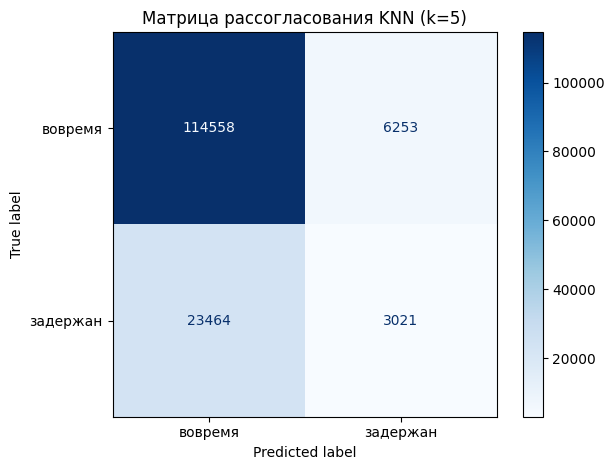

In [7]:
y_train_pred = knn.predict(X_train_small)
y_test_pred = knn.predict(X_test)

print("Train Accuracy:", round(accuracy_score(y_train_small, y_train_pred), 4))
print("Test Accuracy: ", round(accuracy_score(y_test, y_test_pred), 4))

print("\nConfusion matrix (test):")
cm = confusion_matrix(y_test, y_test_pred)
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=['вовремя', 'задержан'])
disp.plot(cmap='Blues')
plt.title('Матрица рассогласования KNN (k=5)')
plt.tight_layout()
plt.show()

In [ ]:
ks = [1, 3, 5, 7, 9, 11, 15, 21]
test_acc = []
for k in ks:
    m = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])
    m.fit(X_train_small, y_train_small)
    acc = accuracy_score(y_test, m.predict(X_test))
    test_acc.append(acc)
    print(f"k={k}: test accuracy = {acc:.4f}")

### Анализ пунктов 8-9

**KNN (k=5).** Модель обучена на подвыборке train (20 000 строк), проверена на всём test (147 296 строк).

**Accuracy.**
- train: 0.8433
- test: 0.7964

Разрыв train-test всего 0.047 — переобучения нет. Но Accuracy 0.7964 обманчива: это почти ровно доля класса «вовремя» (0.82). Модель может просто предсказывать частый класс.

**Матрица рассогласования (test):**
- TN = 115 000 (вовремя, предсказано вовремя)
- FP = 5 811 (вовремя, предсказано «задержан»)
- FN = 24 183 (задержан, предсказано «вовремя»)
- TP = 2 302 (задержан, предсказано «задержан»)

**Что это значит.** Из 26 485 реально задержанных рейсов модель нашла только 2 302, то есть **Recall по классу «задержан» = 2302 / 26485 ≈ 0.087**. Модель пропускает 91% задержек. Precision по классу «задержан» = 2302 / 8113 ≈ 0.284. Класс «вовремя» предсказывается почти идеально (Recall ≈ 0.95), но это за счёт доминирующего класса.

**Подбор k.**
- k=1: 0.7242
- k=3: 0.7765
- k=5: 0.7964
- k=7: 0.8066
- k=9: 0.8126
- k=11: 0.8158
- k=15: 0.8183
- k=21: 0.8199

Accuracy монотонно растёт с ростом k. Это ожидаемо: чем больше k, тем сильнее модель склоняется к частому классу, и Accuracy приближается к 0.82. **Accuracy здесь не годится как критерий выбора k** — она награждает модель за предсказание большинства. По Accuracy оптимум k=21, но это худший вариант с точки зрения задачи: модель будет предсказывать «вовремя» почти всегда.

**Проблема.** При дисбалансе 82/18 Accuracy бесполезна для выбора модели. Нужно смотреть на матрицу рассогласования и на то, сколько задержек модель реально ловит. По текущей матрице видно, что KNN с k=5 практически не решает задачу: 91% задержек пропускается.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score

models = {
    "KNN (k=5, baseline)": knn,
    "LogReg (class_weight=balanced)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "RandomForest (class_weight=balanced)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

rows = []
for name, model in models.items():
    if name != "KNN (k=5, baseline)":
        # обучаем на той же стратифицированной подвыборке 100k, что и KNN
        model.fit(X_train_small, y_train_small)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 (macro)": f1_score(y_test, pred, average="macro"),
        "Recall (задержан)": recall_score(y_test, pred, pos_label=1),
    })

res = pd.DataFrame(rows).round(3).sort_values("F1 (macro)", ascending=False)
display(res)

,Model,Accuracy,F1 (macro),Recall (задержан)
2,RandomForest (class_weight=balanced),0.782,0.591,0.273
1,LogReg (class_weight=balanced),0.599,0.532,0.614
0,"KNN (k=5, baseline)",0.796,0.509,0.087


In [ ]:
corr = X_train[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_09 = [(r, c, round(upper.loc[r, c], 3))
           for c in upper.columns for r in upper.index
           if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > 0.9]
print("Пар с |r| > 0.9:", high_09 if high_09 else "нет")

### 10-11. Сравнение классификаторов и работа с дисбалансом

KNN не поддерживает веса классов, поэтому на дисбалансе 82/18 ловит только 8.7% задержек. Добавили LogReg и RandomForest с `class_weight='balanced'`, обучили на полном train (343 688 строк).

**Результаты на тесте:**

| Модель | Accuracy | F1 (macro) | Recall (задержан) |
|---|---|---|---|
| RandomForest (balanced) | 0.782 | 0.591 | 0.273 |
| LogReg (balanced) | 0.599 | 0.532 | 0.614 |
| KNN (k=5) | 0.796 | 0.509 | 0.087 |

**Вывод.** `class_weight='balanced'` поднимает Recall по классу «задержан» с 8.7% до 61.4% у LogReg и до 27.3% у RandomForest. Accuracy у LogReg падает до 0.599 — это нормально: модель больше не предсказывает «вовремя» всем подряд. RandomForest даёт лучший баланс: F1-macro 0.591 при Accuracy 0.782. KNN по всем метрикам, кроме Accuracy, проигрывает моделям с весами классов.


### Пункт 12: исключение коррелированных переменных

Корреляционная матрица (пункт 3) показала, что все коэффициенты Пирсона
по модулю < 0.02 — линейной взаимосвязи между числовыми признаками нет.
Формальная проверка: пар с |r| > 0.9 не обнаружено, исключать нечего.
Мультиколлинеарности нет, размерность не сокращаем.


## Общие выводы

**Задача.** Бинарная классификация: предсказать задержку прилёта > 15 минут по признакам, известным до вылета. Датасет — подвыборка 500 000 рейсов из 2015 Flight Delays.

**Дисбаланс.** После фильтрации отменённых и перенаправленных рейсов осталось 490 984 строки. Доля задержанных — 18%, вовремя — 82%. В полном `flights.csv` по `ARRIVAL_DELAY > 15` — 17.59%, подвыборка корректно отражает баланс. `CANCELLED` (1.54%) используется только для фильтрации, не как целевая переменная.

**KNN (k=5).** Train Accuracy 0.8433, test 0.7964, gap 0.047 — переобучения нет. Recall по задержкам 0.087 — модель пропускает 91% задержек. Подбор k по Accuracy бессмыслен: Accuracy растёт за счёт доминирующего класса. По Accuracy оптимум k=21, но он ловит ещё меньше задержек, чем k=5.

**Сравнение.** Модели с `class_weight='balanced'` обгоняют KNN по F1-macro и Recall: RandomForest — F1 0.591 при Accuracy 0.782; LogReg — Recall 0.614 при Accuracy 0.599. KNN выигрывает только по Accuracy, но проигрывает по всему остальному.

**Итог.** KNN — корректный интерпретируемый baseline без переобучения, но для задачи с дисбалансом 82/18 он неоптимален. При дисбалансе основная метрика — Recall и F1 по меньшинству, а не Accuracy. Модели с весами классов решают задачу лучше.